# Lab Assignment 6

Efficient Fine-Tuning and Alignment of LLMs: LoRA, QLoRA and RLHF

## Objective
A pretrained language model has billions of parameters. Adapting it to a new task, or aligning it with human
preferences, with naive *full fine-tuning* is far too expensive for most labs. This assignment walks through the
three ideas that make adaptation practical, from the cheapest trick to the most involved procedure:

1. **LoRA (Part A)** — freeze the pretrained weights and learn only a tiny *low-rank* update. You implement the
   forward pass, the gradients, and training by hand, and discover how the rank controls what can be learned.
2. **QLoRA (Part B)** — additionally store the frozen base weights in **4-bit**, so that big models fit on small
   GPUs. You implement block-wise quantisation (uniform int4 and the NormalFloat NF4 code book) and train
   LoRA adapters on top of a quantised base.
3. **RLHF (Part C)** — align a model with human preferences. You train a **reward model** from pairwise
   comparisons (Bradley–Terry), then optimise a policy against it with a **KL penalty** to the reference model,
   and watch **reward hacking** happen when the KL penalty is too weak. (Bonus: DPO.)
4. **The real libraries (Part D)** — repeat LoRA and QLoRA on a real transformer using `peft` and `bitsandbytes`.

Parts A–C use a *toy* "LLM layer" and a *toy* response space so that everything runs in seconds on a laptop CPU
and every gradient can be derived and verified by hand. The mathematics is exactly what real systems use.

> **Read Tutorial 6 first** (`Tutorial_6_LoRA_QLoRA_RLHF.ipynb`). It explains each idea with small worked examples
> and tells you what each task below expects.

## Submission
- Complete all `TODO` sections and all markdown answers.
- Do not modify the supplied test cells (the `assert` statements must pass as-is).
- Parts A, B and C: only `numpy`, `matplotlib`, `random` and the Python standard library — no ML libraries.
  Part D is the one place you are allowed (in fact required) to use `torch`, `transformers`, `peft` and
  `bitsandbytes`. Part D is meant for Google Colab (free T4 GPU). If you have no GPU, do D1 and answer D2 in
  words instead (see the note in Part D).
- Run **Kernel > Restart & Run All** before submitting the completed `.ipynb` file. Cells run in order and later
  cells reuse functions defined earlier (for example `numeric_grad` from Task A2).
- Keep the random seeds as given so that your numbers are reproducible.

## Structure
| Part | Content |
|---|---|
| A | LoRA: init/forward/merge, backward + gradient check, training + rank sweep |
| B | QLoRA: block-wise int4, NF4, QLoRA training + memory |
| C | RLHF: reward model, KL-regularised policy optimisation, reward hacking |
| D | `peft` LoRA and `bitsandbytes` QLoRA on a real model |
| Analysis | Five short questions at the end |
| Bonus | DPO (Task C4) |

# Part A: LoRA from Scratch

A linear layer computes $y = xW_0$ with a pretrained weight $W_0 \in \mathbb{R}^{d_{in}\times d_{out}}$
(we use the *row-vector* convention: $x$ is a row, a batch is a matrix with one row per example).

**Full fine-tuning** would update all $d_{in} d_{out}$ entries of $W_0$. **LoRA** (Low-Rank Adaptation) instead
keeps $W_0$ **frozen** and learns a low-rank correction:

$$
y = x W_0 + \frac{\alpha}{r}\, x A B, \qquad A \in \mathbb{R}^{d_{in}\times r},\; B \in \mathbb{R}^{r\times d_{out}},\; r \ll \min(d_{in}, d_{out}).
$$

Only $A$ and $B$ are trained: $r(d_{in}+d_{out})$ numbers instead of $d_{in}d_{out}$. The factor $\alpha/r$ is a
fixed scale. Initialisation matters: $A$ is random and **$B$ is zero**, so at the start the adapted model is
*exactly* the pretrained model.

### Task A1: Initialisation, forward pass, merging

1. `lora_init(d_in, d_out, r)` — return `A` (shape `d_in x r`, entries $\mathcal{N}(0, 1/d_{in})$, i.e.
   `np.random.randn(d_in, r) / np.sqrt(d_in)`) and `B` (zeros, shape `r x d_out`).
2. `lora_forward(x, W0, A, B, alpha)` — the formula above, with `r = A.shape[1]`.
3. `merge_lora(W0, A, B, alpha)` — return a single matrix $W = W_0 + \frac{\alpha}{r}AB$. After training, merging
   removes all inference overhead.
4. `count_params(*arrays)` — total number of scalar entries in the given arrays.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

random.seed(0)
np.random.seed(0)


def lora_init(d_in, d_out, r):
    # A ~ N(0, 1/d_in) with shape (d_in, r); B = zeros with shape (r, d_out)
    A = np.random.randn(d_in, r) / np.sqrt(d_in)
    B = np.zeros((r, d_out))
    return A, B


def lora_forward(x, W0, A, B, alpha):
    r = A.shape[1]
    return x @ W0 + (alpha / r) * (x @ A) @ B


def merge_lora(W0, A, B, alpha):
    r = A.shape[1]
    return W0 + (alpha / r) * (A @ B)


def count_params(*arrays):
    return int(sum(a.size for a in arrays))


# --- test cases: do not modify ---
np.random.seed(0)
d_in, d_out, r = 16, 12, 4
W0 = np.random.randn(d_in, d_out)
A, B = lora_init(d_in, d_out, r)
assert A.shape == (d_in, r) and B.shape == (r, d_out)
assert np.allclose(B, 0) and not np.allclose(A, 0)

x = np.random.randn(5, d_in)
# with B = 0 the adapted layer must equal the base layer
assert np.allclose(lora_forward(x, W0, A, B, alpha=8), x @ W0)

# with a non-zero B, merging must give identical outputs
B_test = np.random.randn(r, d_out)
y_lora = lora_forward(x, W0, A, B_test, alpha=8)
W_merged = merge_lora(W0, A, B_test, alpha=8)
assert W_merged.shape == W0.shape
assert np.allclose(y_lora, x @ W_merged)

assert count_params(A, B) == r * (d_in + d_out)
assert count_params(W0) == d_in * d_out
print("Task A1 checks passed.")
print(f"Full layer: {count_params(W0)} params | LoRA r={r}: {count_params(A, B)} params")

Task A1 checks passed.
Full layer: 192 params | LoRA r=4: 112 params


### Task A2: Backward pass and gradient check

We use the loss $L = \frac{1}{2N}\sum_{n=1}^{N}\lVert \hat y_n - y_n\rVert^2$ (`mse_loss`, supplied).
With $\hat Y = XW_0 + s\,XAB$ and $s=\alpha/r$, let $dY = \partial L/\partial \hat Y = (\hat Y - Y)/N$. Then

$$
\frac{\partial L}{\partial B} = s\,(XA)^\top dY, \qquad
\frac{\partial L}{\partial A} = s\,X^\top\!\big(dY\,B^\top\big).
$$

$W_0$ is **frozen**: it receives no gradient and is never updated. Implement `lora_backward` returning `dA, dB`.

You then *prove* your gradients are right with a **numerical gradient check**: compare against central finite
differences $\frac{f(\theta+\epsilon)-f(\theta-\epsilon)}{2\epsilon}$. `numeric_grad` is supplied. Gradient
checking is the single most useful debugging tool when writing backprop by hand.

In [2]:
def mse_loss(y_pred, y_true):
    # supplied: L = 1/(2N) * sum_n ||y_pred_n - y_true_n||^2
    return 0.5 * np.mean(np.sum((y_pred - y_true) ** 2, axis=1))


def numeric_grad(f, X, eps=1e-6):
    # supplied: central-difference gradient of scalar function f at array X
    g = np.zeros_like(X, dtype=float)
    it = np.nditer(X, flags=["multi_index"])
    for _ in it:
        i = it.multi_index
        old = X[i]
        X[i] = old + eps; fp = f(X)
        X[i] = old - eps; fm = f(X)
        X[i] = old
        g[i] = (fp - fm) / (2 * eps)
    return g


def lora_backward(x, y_pred, y_true, A, B, alpha):
    # W0 is frozen, so it gets no gradient
    N = len(x)
    s = alpha / A.shape[1]
    dY = (y_pred - y_true) / N
    dB = s * (x @ A).T @ dY
    dA = s * x.T @ (dY @ B.T)
    return dA, dB


# --- test cases: do not modify ---
np.random.seed(3)
d_in_t, d_out_t, r_t, N_t = 6, 5, 3, 8
W0_t = np.random.randn(d_in_t, d_out_t)
A_t = np.random.randn(d_in_t, r_t)
B_t = np.random.randn(r_t, d_out_t)          # non-zero, otherwise dA would be exactly 0
x_t = np.random.randn(N_t, d_in_t)
y_t = np.random.randn(N_t, d_out_t)
alpha_t = 6

y_pred_t = lora_forward(x_t, W0_t, A_t, B_t, alpha_t)
dA_t, dB_t = lora_backward(x_t, y_pred_t, y_t, A_t, B_t, alpha_t)
assert dA_t.shape == A_t.shape and dB_t.shape == B_t.shape

num_dA = numeric_grad(lambda A_: mse_loss(lora_forward(x_t, W0_t, A_, B_t, alpha_t), y_t), A_t)
num_dB = numeric_grad(lambda B_: mse_loss(lora_forward(x_t, W0_t, A_t, B_, alpha_t), y_t), B_t)
rel_err = lambda a, b: np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b) + 1e-12)
print("relative error dA:", rel_err(dA_t, num_dA), "| dB:", rel_err(dB_t, num_dB))
assert rel_err(dA_t, num_dA) < 1e-5
assert rel_err(dB_t, num_dB) < 1e-5
print("Task A2 gradient check passed.")

relative error dA: 1.5205563553186807e-10 | dB: 1.876389674779124e-10
Task A2 gradient check passed.


### Task A3: Train LoRA and sweep the rank

**The toy task.** A "pretrained" layer `W_base` (64 x 64) has to be adapted to a new task whose true weight is
`W_target = W_base + Delta`, where `Delta` is a **rank-2** matrix (that is the whole premise of LoRA: the
change needed for a new task is low-rank). We observe noisy input/output pairs from `W_target`.

1. Write `train_lora(x, y, W0, r, alpha, lr, steps, seed)`: initialise with `lora_init`, then for each step do
   forward &rarr; loss (append to `losses`) &rarr; `lora_backward` &rarr; gradient-descent update of **`A` and `B`
   only**. Return `A, B, losses`.
2. Plot the training-loss curve (log-scale y-axis) for `r = 2`.
3. **Rank sweep:** train with `r` in `[1, 2, 4, 8, 16]` (use `alpha = 2 * r`), record the **validation** loss and
   the number of trainable parameters for each, and plot validation loss against `r`, with the full fine-tuning
   result (supplied function `full_finetune`) as a horizontal reference line.

In [3]:
# --- supplied: the toy fine-tuning task (do not modify) ---
np.random.seed(1)
D = 64
W_base = np.random.randn(D, D) / np.sqrt(D)                     # "pretrained" weight
Delta = 0.03 * (np.random.randn(D, 2) @ np.random.randn(2, D))  # the needed change: rank 2
W_target = W_base + Delta

X_train = np.random.randn(1024, D)
X_val = np.random.randn(256, D)
Y_train = X_train @ W_target + 0.01 * np.random.randn(1024, D)
Y_val = X_val @ W_target + 0.01 * np.random.randn(256, D)

print("Validation loss of the un-adapted base model:", mse_loss(X_val @ W_base, Y_val))
print("Rank of the true update Delta:", np.linalg.matrix_rank(Delta))


def full_finetune(x, y, W0, lr=0.1, steps=500):
    # supplied baseline: update ALL entries of W (D*D parameters)
    W = W0.copy()
    N = len(x)
    for _ in range(steps):
        dY = (x @ W - y) / N
        W -= lr * (x.T @ dY)
    return W

Validation loss of the un-adapted base model: 5.144764873204236
Rank of the true update Delta: 2


In [4]:
def train_lora(x, y, W0, r, alpha, lr=0.1, steps=500, seed=0):
    np.random.seed(seed)
    A, B = lora_init(W0.shape[0], W0.shape[1], r)
    losses = []
    for _ in range(steps):
        y_pred = lora_forward(x, W0, A, B, alpha)
        losses.append(mse_loss(y_pred, y))
        dA, dB = lora_backward(x, y_pred, y, A, B, alpha)
        A -= lr * dA          # only the adapters are updated
        B -= lr * dB          # W0 is never touched
    return A, B, losses


# --- test cases: do not modify ---
W_base_copy = W_base.copy()
A2_, B2_, losses = train_lora(X_train, Y_train, W_base, r=2, alpha=4)
assert np.array_equal(W_base, W_base_copy), "the frozen weight must not change"
val_loss_r2 = mse_loss(lora_forward(X_val, W_base, A2_, B2_, 4), Y_val)
print(f"train loss: {losses[0]:.4f} -> {losses[-1]:.5f} | validation loss (r=2): {val_loss_r2:.5f}")
assert len(losses) == 500
assert losses[-1] < 0.01 * losses[0]
assert val_loss_r2 < 0.05
assert count_params(A2_, B2_) == 2 * (D + D)
print("Task A3 (training) checks passed.")

train loss: 5.3892 -> 0.00316 | validation loss (r=2): 0.00321
Task A3 (training) checks passed.


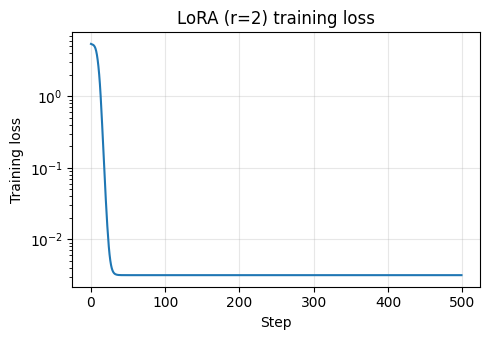

In [5]:
plt.figure(figsize=(5, 3.5))
plt.semilogy(losses)
plt.xlabel("Step"); plt.ylabel("Training loss"); plt.title("LoRA (r=2) training loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


  r | trainable params | validation loss
  1 |              128 |        2.427162
  2 |              256 |        0.003215
  4 |              512 |        0.003219
  8 |            1,024 |        0.003229
 16 |            2,048 |        0.003249
full fine-tuning (4,096 params): validation loss = 0.003430


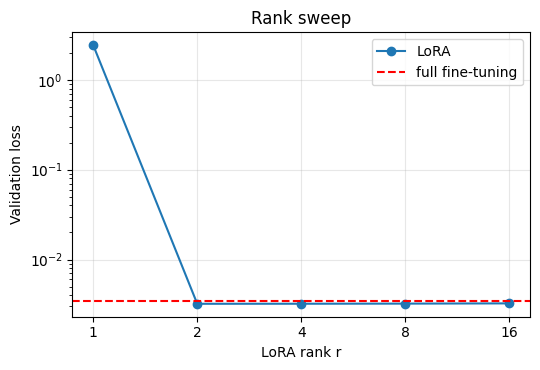

Task A3 (rank sweep) checks passed.


In [6]:
ranks = [1, 2, 4, 8, 16]
sweep_val_loss = {}      # r -> validation loss
sweep_params = {}        # r -> number of trainable parameters

for r_ in ranks:
    A_r, B_r, _ = train_lora(X_train, Y_train, W_base, r=r_, alpha=2 * r_)
    sweep_val_loss[r_] = mse_loss(lora_forward(X_val, W_base, A_r, B_r, 2 * r_), Y_val)
    sweep_params[r_] = count_params(A_r, B_r)

W_full = full_finetune(X_train, Y_train, W_base)
full_val = mse_loss(X_val @ W_full, Y_val)

print(f"{'r':>3} | {'trainable params':>16} | {'validation loss':>15}")
for r_ in ranks:
    print(f"{r_:>3} | {sweep_params[r_]:>16,} | {sweep_val_loss[r_]:>15.6f}")
print(f"full fine-tuning ({count_params(W_base):,} params): validation loss = {full_val:.6f}")

plt.figure(figsize=(5.5, 3.8))
plt.semilogy(ranks, [sweep_val_loss[r_] for r_ in ranks], "o-", label="LoRA")
plt.axhline(full_val, color="r", linestyle="--", label="full fine-tuning")
plt.xscale("log", base=2)
plt.xticks(ranks, [str(r_) for r_ in ranks])
plt.xlabel("LoRA rank r"); plt.ylabel("Validation loss")
plt.title("Rank sweep"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# --- test cases: do not modify ---
assert set(sweep_val_loss) == set(ranks) and set(sweep_params) == set(ranks)
assert sweep_val_loss[1] > 10 * sweep_val_loss[2], "rank 1 cannot represent a rank-2 update"
assert sweep_val_loss[2] < 0.05
assert sweep_params[16] == 16 * (D + D)
print("Task A3 (rank sweep) checks passed.")

# Part B: QLoRA — a 4-bit Frozen Base

LoRA shrinks the *trainable* parameters, but the frozen base model still has to sit in GPU memory. A 7B-parameter
model in 16-bit needs about 14 GB just for the weights. **QLoRA** stores the frozen base weights in **4 bits**
and *de-quantises them on the fly* inside the forward pass, while the LoRA adapters $A, B$ stay in higher
precision and receive all the gradients:

$$
y = x\,\underbrace{\mathrm{deq}(W_0^{4\text{-bit}})}_{\text{frozen}} + \frac{\alpha}{r}\, x A B .
$$

### Task B1: Block-wise 4-bit quantisation

Quantising a whole tensor with one scale is fragile: a single outlier stretches the scale and crushes all the
other weights to zero. So weights are cut into **blocks** (we use 64 values), each with its own scale.

For each block: `absmax = max(|w|)`, then `code = round(w / absmax * 7)` which is an integer in $[-7, 7]$ (that
is 15 levels, a symmetric signed 4-bit code), and de-quantisation is `code / 7 * absmax`.

1. `quantize_blockwise(w, block_size=64)` — flatten `w`, reshape to `(-1, block_size)`, return
   `codes` (dtype `np.int8`, shape `(n_blocks, block_size)`) and `absmax` (shape `(n_blocks, 1)`). Handle blocks
   whose `absmax` is 0 (no division by zero).
2. `dequantize_blockwise(codes, absmax, shape)` — return the reconstruction reshaped to `shape`.
3. **Block-size experiment:** for a tensor with one big outlier, compare the reconstruction MSE using
   `block_size = 64` against a single block for the whole tensor (`block_size = 4096`).

In [7]:
def quantize_blockwise(w, block_size=64):
    blocks = np.asarray(w).reshape(-1, block_size)
    absmax = np.max(np.abs(blocks), axis=1, keepdims=True)
    safe_absmax = np.where(absmax == 0, 1.0, absmax)       # avoid division by zero
    codes = np.round(blocks / safe_absmax * 7).astype(np.int8)
    return codes, absmax


def dequantize_blockwise(codes, absmax, shape):
    return (codes.astype(np.float64) / 7 * absmax).reshape(shape)


# --- test cases: do not modify ---
np.random.seed(5)
w_test = np.random.randn(8, 64) * 0.1
codes, absmax = quantize_blockwise(w_test, 64)
assert codes.dtype == np.int8 and codes.min() >= -7 and codes.max() <= 7
assert codes.shape == (8, 64) and absmax.shape == (8, 1)
w_hat = dequantize_blockwise(codes, absmax, w_test.shape)
assert w_hat.shape == w_test.shape
# every reconstruction error is at most half a quantisation step of its own block
assert np.all(np.abs(w_test - w_hat) <= (absmax / 7 / 2) + 1e-12)
# an all-zero block must survive
z = np.zeros((1, 64)); cz, az = quantize_blockwise(z, 64)
assert np.all(dequantize_blockwise(cz, az, z.shape) == 0)
print("Task B1 checks passed.")

Task B1 checks passed.


In [8]:
# Block-size experiment: one outlier in a tensor of 4096 weights.
np.random.seed(6)
w_out = np.random.randn(4096) * 0.05
w_out[100] = 5.0                       # a single outlier
mse_by_block = {}                      # block_size -> reconstruction MSE

for bs in [64, 4096]:
    c_, a_ = quantize_blockwise(w_out, bs)
    w_hat_ = dequantize_blockwise(c_, a_, w_out.shape)
    mse_by_block[bs] = np.mean((w_out - w_hat_) ** 2)

# --- test cases: do not modify ---
assert set(mse_by_block) == {64, 4096}
print(mse_by_block)
assert mse_by_block[64] < 0.1 * mse_by_block[4096]
print("Task B1 (block-size experiment) passed.")

{64: np.float64(5.989594705669992e-05), 4096: np.float64(0.0023293260949828806)}
Task B1 (block-size experiment) passed.


### Task B2: NormalFloat-4 (NF4)

Uniform levels are not the best use of only 16 values. Trained weights are roughly **bell-shaped**, so most of
them are small. **NF4** places its 16 levels at (normalised) quantiles of a standard normal distribution: more
levels near 0 where the weights are dense, fewer in the tails. After dividing a block by its `absmax` the values
lie in $[-1,1]$, and each value is snapped to the **nearest** of the 16 NF4 levels (supplied below).

1. `quantize_nf4(w, block_size=64)` — returns `idx` (dtype `np.uint8`, values 0..15, shape `(n_blocks, block_size)`,
   the index of the nearest level) and `absmax` (shape `(n_blocks, 1)`).
2. `dequantize_nf4(idx, absmax, shape)` — `NF4_LEVELS[idx] * absmax`, reshaped.
3. On 32,000 Gaussian weights, compare the reconstruction MSE of NF4 against the uniform int4 of Task B1 and print both.

In [9]:
NF4_LEVELS = np.array([
    -1.0, -0.6961928009986877, -0.5250730514526367, -0.39491748809814453,
    -0.28444138169288635, -0.18477343022823334, -0.09105003625154495, 0.0,
    0.07958029955625534, 0.16093020141124725, 0.24611230194568542, 0.33791524171829224,
    0.44070982933044434, 0.5626170039558411, 0.7229568362236023, 1.0,
])  # supplied: the 16 NF4 code-book values


def quantize_nf4(w, block_size=64):
    blocks = np.asarray(w).reshape(-1, block_size)
    absmax = np.max(np.abs(blocks), axis=1, keepdims=True)
    safe_absmax = np.where(absmax == 0, 1.0, absmax)
    normalised = blocks / safe_absmax
    idx = np.abs(normalised[..., None] - NF4_LEVELS).argmin(-1)   # nearest of the 16 levels
    return idx.astype(np.uint8), absmax


def dequantize_nf4(idx, absmax, shape):
    return (NF4_LEVELS[idx] * absmax).reshape(shape)


# --- test cases: do not modify ---
np.random.seed(7)
w_gauss = np.random.randn(64 * 500)
idx, am = quantize_nf4(w_gauss, 64)
assert idx.dtype == np.uint8 and idx.max() <= 15 and idx.shape == (500, 64)
w_nf4 = dequantize_nf4(idx, am, w_gauss.shape)
c_u, a_u = quantize_blockwise(w_gauss, 64)
w_int4 = dequantize_blockwise(c_u, a_u, w_gauss.shape)
mse_nf4 = np.mean((w_gauss - w_nf4) ** 2)
mse_int4 = np.mean((w_gauss - w_int4) ** 2)
print(f"MSE int4: {mse_int4:.5f} | MSE NF4: {mse_nf4:.5f}")
assert mse_nf4 < mse_int4
print("Task B2 checks passed.")

MSE int4: 0.01167 | MSE NF4: 0.00840
Task B2 checks passed.


### Task B3: Train a QLoRA layer and count the memory

**Part 1 — QLoRA training.** Quantise the frozen base `W_base` from Task A3 to int4 and to NF4 (block size 64),
de-quantise each back to a float matrix (that is what the forward pass would use), and train LoRA (`r = 2`,
`alpha = 4`) on top of it with your `train_lora` from Task A3 — pass the **de-quantised** matrix as `W0`. For each
of `fp` (original `W_base`), `int4` and `nf4` record `(validation loss before training, validation loss after
training)` in the dictionary `qlora_results`. The adapters have to fit the new task *and* can partly repair the
damage done by quantisation.

**Part 2 — memory.** Write `model_memory_gb(n_params, mode, trainable_fraction=0.01, block_size=64)` using this
simplified accounting (activations are ignored):

| mode | bytes per parameter |
|---|---|
| `"full"` | 16 (fp16 weight 2 + fp16 gradient 2 + fp32 master copy 4 + Adam $m,v$ 8) |
| `"lora"` | 2 (frozen fp16 base) $+\ 16\times$ `trainable_fraction` |
| `"qlora"` | $0.5 + 2/$`block_size` (4-bit code + one fp16 `absmax` per block) $+\ 16\times$ `trainable_fraction` |

Return gigabytes (`1 GB = 1e9` bytes).

In [10]:
# Part 1: QLoRA training on a quantised base
qlora_results = {}     # name -> (val loss before, val loss after)

c4, a4 = quantize_blockwise(W_base, 64)
W_int4 = dequantize_blockwise(c4, a4, W_base.shape)
i4, an4 = quantize_nf4(W_base, 64)
W_nf4 = dequantize_nf4(i4, an4, W_base.shape)

print("Weight reconstruction MSE  int4:", np.mean((W_base - W_int4) ** 2),
      "| nf4:", np.mean((W_base - W_nf4) ** 2))

for name, W0 in [("fp", W_base), ("int4", W_int4), ("nf4", W_nf4)]:
    before = mse_loss(X_val @ W0, Y_val)
    A_, B_, _ = train_lora(X_train, Y_train, W0, r=2, alpha=4)
    after = mse_loss(lora_forward(X_val, W0, A_, B_, 4), Y_val)
    qlora_results[name] = (before, after)

for k, (b, a) in qlora_results.items():
    print(f"{k:>5}: before {b:.4f} -> after {a:.4f}")

# --- test cases: do not modify ---
assert set(qlora_results) == {"fp", "int4", "nf4"}
for k, (b, a) in qlora_results.items():
    assert a < 0.1 * b, k
assert qlora_results["fp"][1] < qlora_results["nf4"][1] < qlora_results["int4"][1]
print("Task B3 (training) checks passed.")

Weight reconstruction MSE  int4: 0.00018008121412913124 | nf4: 0.00013489660125560538
   fp: before 5.1448 -> after 0.0032
 int4: before 5.5220 -> after 0.3480
  nf4: before 5.4513 -> after 0.2611
Task B3 (training) checks passed.


In [11]:
def model_memory_gb(n_params, mode, trainable_fraction=0.01, block_size=64):
    if mode == "full":
        bytes_per_param = 16.0
    elif mode == "lora":
        bytes_per_param = 2.0 + 16.0 * trainable_fraction
    elif mode == "qlora":
        bytes_per_param = 0.5 + 2.0 / block_size + 16.0 * trainable_fraction
    else:
        raise ValueError(f"unknown mode: {mode}")
    return n_params * bytes_per_param / 1e9


# --- test cases: do not modify ---
n7b = 7e9
full, lora, qlora = (model_memory_gb(n7b, m) for m in ["full", "lora", "qlora"])
print(f"7B model  full: {full:.1f} GB | LoRA: {lora:.1f} GB | QLoRA: {qlora:.1f} GB")
assert np.isclose(full, 112.0)
assert np.isclose(lora, 15.12)
assert np.isclose(qlora, 4.83875)
assert qlora < lora < full
print("Task B3 (memory) checks passed.")

7B model  full: 112.0 GB | LoRA: 15.1 GB | QLoRA: 4.8 GB
Task B3 (memory) checks passed.


# Part C: RLHF — Reward Model, KL-Regularised Policy, Reward Hacking

**Reinforcement Learning from Human Feedback** aligns a model with what people prefer, in three stages:

1. **SFT** — supervised fine-tuning gives a reference policy $\pi_{ref}$ (we just take it as given).
2. **Reward model** — humans compare two responses; we fit a scalar reward $r_\phi(x)$ so that the preferred one
   scores higher (**Bradley–Terry**): $P(a \succ b) = \sigma\big(r(a) - r(b)\big)$.
3. **Policy optimisation** — maximise reward while staying close to $\pi_{ref}$:
$$
\max_\pi\; \mathbb{E}_{a\sim\pi}\big[r(a)\big] \;-\; \beta\, \mathrm{KL}\big(\pi \,\Vert\, \pi_{ref}\big).
$$
   The KL term is what stops the policy from "exploiting" the (imperfect) reward model.

**Toy world.** A "response" is described by 3 numbers: how **helpful** it is, how **polite**, and how **long**.
Human raters like helpful and polite answers, mildly like longer answers, but *hate extreme rambling*:

$$
r_{true}(h,p,\ell) = h + 0.5\,p + 0.3\,\ell - 1.0\cdot\max(0,\ell-1.5)^2 .
$$

Our **reward model is linear**, $r_w(x) = w^\top x$, and it will only ever see responses of moderate length
(`length` is clipped to $[-1.5, 1.5]$ in the comparison data), so it cannot know about the rambling penalty.
Keep this in mind for Task C3.

### Task C1: Reward model from pairwise preferences

For a chosen response $x_c$ and a rejected one $x_r$, with $d = x_c - x_r$, the Bradley–Terry loss is
$$
L(w) = -\frac{1}{M}\sum_m \log \sigma(w^\top d_m),\qquad
\nabla_w L = -\frac{1}{M}\sum_m \big(1-\sigma(w^\top d_m)\big)\, d_m .
$$

1. `sigmoid(z)` — **numerically stable** (no overflow warnings for $z=\pm 1000$). Hint: use $e^{-|z|}$.
2. `preference_loss(w, X_chosen, X_rejected)` and `preference_grad(...)`.
   (Hint: $-\log\sigma(z) = \log(1+e^{-z})$ = `np.logaddexp(0, -z)`.)
3. `train_reward_model(X_chosen, X_rejected, lr=0.5, steps=3000)` — gradient descent from `w = 0`; return `w`
   and the list of losses.

In [12]:
# --- supplied: synthetic preference data (do not modify) ---
def true_reward(X):
    h, p, l = X[:, 0], X[:, 1], X[:, 2]
    return h + 0.5 * p + 0.3 * l - 1.0 * np.maximum(0.0, l - 1.5) ** 2


def sample_responses(rng, n):
    h = rng.randn(n); p = rng.randn(n)
    l = np.clip(0.8 * h + 0.6 * rng.randn(n), -1.5, 1.5)   # moderate lengths only, correlated with helpfulness
    return np.stack([h, p, l], axis=1)


rng_data = np.random.RandomState(0)
pool = sample_responses(rng_data, 400)
r_pool = true_reward(pool)
ia = rng_data.randint(0, 400, 300); ib = rng_data.randint(0, 400, 300)
# humans are noisy: they pick a over b with probability sigmoid(r(a) - r(b))
a_wins = rng_data.rand(300) < 1 / (1 + np.exp(-(r_pool[ia] - r_pool[ib])))
X_chosen = np.where(a_wins[:, None], pool[ia], pool[ib])
X_rejected = np.where(a_wins[:, None], pool[ib], pool[ia])

# a clean held-out set (labels from the true reward, no noise) to measure how well the model ranks
rng_val = np.random.RandomState(1)
Xv_a, Xv_b = sample_responses(rng_val, 1000), sample_responses(rng_val, 1000)
val_label = true_reward(Xv_a) > true_reward(Xv_b)
print("training comparisons:", len(X_chosen), "| held-out pairs:", len(val_label))

training comparisons: 300 | held-out pairs: 1000


In [13]:
def sigmoid(z):
    z = np.asarray(z, dtype=float)
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def preference_loss(w, X_chosen, X_rejected):
    z = (X_chosen - X_rejected) @ w
    return np.mean(np.logaddexp(0, -z))


def preference_grad(w, X_chosen, X_rejected):
    d = X_chosen - X_rejected
    z = d @ w
    return -np.mean((1.0 - sigmoid(z))[:, None] * d, axis=0)


def train_reward_model(X_chosen, X_rejected, lr=0.5, steps=3000):
    w = np.zeros(X_chosen.shape[1])
    losses = []
    for _ in range(steps):
        losses.append(preference_loss(w, X_chosen, X_rejected))
        w = w - lr * preference_grad(w, X_chosen, X_rejected)
    return w, losses


# --- test cases: do not modify ---
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("error")                    # any overflow warning becomes an error
    s = sigmoid(np.array([-1000.0, 0.0, 1000.0]))
assert np.allclose(s, [0.0, 0.5, 1.0])

w_chk = np.array([0.3, -0.2, 0.5])
g = preference_grad(w_chk, X_chosen, X_rejected)
g_num = numeric_grad(lambda w_: preference_loss(w_, X_chosen, X_rejected), w_chk)
assert np.allclose(g, g_num, atol=1e-6), (g, g_num)

w_rm, rm_losses = train_reward_model(X_chosen, X_rejected)
assert rm_losses[-1] < rm_losses[0]
acc = np.mean(((Xv_a @ w_rm) > (Xv_b @ w_rm)) == val_label)
print("learned reward weights [helpful, polite, length]:", np.round(w_rm, 2))
print("true weights inside the training range:           [1.0, 0.5, 0.3]")
print(f"held-out ranking accuracy: {acc:.3f}")
assert acc > 0.9
print("Task C1 checks passed.")

learned reward weights [helpful, polite, length]: [1.1  0.59 0.2 ]
true weights inside the training range:           [1.0, 0.5, 0.3]
held-out ranking accuracy: 0.980
Task C1 checks passed.


### Task C2: KL-regularised policy optimisation

Now the "language model" is a **policy over 8 candidate responses**: $\pi_\theta(a) = \mathrm{softmax}(\theta)_a$.
The candidates' features, the reference policy $\pi_{ref}$ and the **proxy reward** (your learned reward model
applied to the candidates) are supplied. Implement:

1. `log_softmax(z)` — stable ($z - \max z - \log\sum e^{z-\max z}$).
2. `kl_divergence(p, q)` — $\sum_a p_a(\log p_a - \log q_a)$, with `0 log 0 = 0`.
3. `rlhf_objective(pi, reward, pi_ref, beta)` — $\mathbb{E}_\pi[r]-\beta\,\mathrm{KL}(\pi\Vert\pi_{ref})$.
4. `optimal_policy(reward, pi_ref, beta)` — the **closed-form maximiser**
   $\pi^*(a) \propto \pi_{ref}(a)\,\exp\big(r(a)/\beta\big)$. Compute it stably as
   `softmax(log(pi_ref) + reward / beta)`.
5. `reinforce_step(theta, reward, logp_ref, beta, lr, n_samples, rng)` — one **policy-gradient (REINFORCE)** step.
   Sample `n_samples` actions $a_i \sim \pi_\theta$; use the *shaped* reward
   $\tilde r_i = r(a_i) - \beta\big(\log\pi_\theta(a_i) - \log\pi_{ref}(a_i)\big)$, subtract the batch mean as a
   baseline to get advantages $A_i$, and ascend with
   $\nabla_\theta \approx \frac{1}{n}\sum_i A_i\,(\mathbf{e}_{a_i} - \pi_\theta)$, that is
   `theta += lr * grad`. Return the updated `theta`.
   (Why $\mathbf{e}_a - \pi$? It is $\nabla_\theta \log\pi_\theta(a)$ for a softmax.)

Then train for 400 steps with $\beta = 0.5$ and check that sampling-based RL ends up where the closed form says.

In [14]:
# --- supplied: the toy response space (do not modify) ---
cands = np.array([[0.2, 0.1, 0.1], [0.8, 0.4, 0.6], [1.2, 0.6, 0.9], [0.0, -0.5, -0.3],
                  [-0.6, 0.2, -0.5], [0.5, 0.9, 0.4], [1.0, 0.5, 6.0], [1.0, 0.3, 1.2]])
cand_names = ["short", "ok", "great", "terse", "poor", "polite", "RAMBLER", "long"]
K = len(cands)
proxy_reward = cands @ w_rm              # what the reward model believes (what RL will optimise)
true_rew = true_reward(cands)            # what humans would really think (RL never sees this)

ref_logits = np.array([1.0, 0.8, 0.2, 0.9, 0.5, 0.6, -1.5, 0.1])
pi_ref = np.exp(ref_logits - ref_logits.max()); pi_ref /= pi_ref.sum()
logp_ref = np.log(pi_ref)

print(f"{'candidate':>10} | {'pi_ref':>6} | {'proxy':>6} | {'true':>7}")
for k in range(K):
    print(f"{cand_names[k]:>10} | {pi_ref[k]:6.3f} | {proxy_reward[k]:6.2f} | {true_rew[k]:7.2f}")

 candidate | pi_ref |  proxy |    true
     short |  0.202 |   0.30 |    0.28
        ok |  0.166 |   1.23 |    1.18
     great |  0.091 |   1.85 |    1.77
     terse |  0.183 |  -0.35 |   -0.34
      poor |  0.123 |  -0.64 |   -0.65
    polite |  0.136 |   1.16 |    1.07
   RAMBLER |  0.017 |   2.60 |  -17.20
      long |  0.082 |   1.52 |    1.51


In [15]:
def log_softmax(z):
    z = np.asarray(z, dtype=float)
    zs = z - np.max(z, axis=-1, keepdims=True)
    return zs - np.log(np.sum(np.exp(zs), axis=-1, keepdims=True))


def kl_divergence(p, q):
    p = np.asarray(p, dtype=float); q = np.asarray(q, dtype=float)
    mask = p > 0                                   # 0 * log 0 = 0
    return float(np.sum(p[mask] * (np.log(p[mask]) - np.log(q[mask]))))


def rlhf_objective(pi, reward, pi_ref, beta):
    return float(pi @ reward - beta * kl_divergence(pi, pi_ref))


def optimal_policy(reward, pi_ref, beta):
    return np.exp(log_softmax(np.log(pi_ref) + reward / beta))


def reinforce_step(theta, reward, logp_ref, beta, lr, n_samples, rng):
    K_ = len(theta)
    logp = log_softmax(theta)
    pi = np.exp(logp)
    a = rng.choice(K_, size=n_samples, p=pi)                       # a_i ~ pi_theta
    shaped = reward[a] - beta * (logp[a] - logp_ref[a])            # KL-shaped reward
    adv = shaped - shaped.mean()                                   # baseline
    onehot = np.zeros((n_samples, K_)); onehot[np.arange(n_samples), a] = 1.0
    grad = np.mean(adv[:, None] * (onehot - pi), axis=0)           # grad of log pi for a softmax
    return theta + lr * grad


# --- test cases: do not modify ---
z_big = np.array([1000.0, 1000.0, -1000.0])
assert np.allclose(np.exp(log_softmax(z_big)), [0.5, 0.5, 0.0])
assert np.isclose(kl_divergence(pi_ref, pi_ref), 0.0, atol=1e-12)
assert kl_divergence(np.array([0.9, 0.1]), np.array([0.5, 0.5])) > 0
assert np.isclose(kl_divergence(np.array([1.0, 0.0]), np.array([0.5, 0.5])), np.log(2))

for beta_ in [0.1, 1.0]:
    star = optimal_policy(proxy_reward, pi_ref, beta_)
    assert np.isclose(star.sum(), 1.0) and np.all(star >= 0)
    best = rlhf_objective(star, proxy_reward, pi_ref, beta_)
    rs = np.random.RandomState(0)
    for _ in range(200):                      # no random policy may beat the closed form
        other = rs.dirichlet(np.ones(K))
        assert rlhf_objective(other, proxy_reward, pi_ref, beta_) <= best + 1e-9
assert np.allclose(optimal_policy(proxy_reward, pi_ref, 1e6), pi_ref, atol=1e-4)    # huge beta -> stay at reference
assert optimal_policy(proxy_reward, pi_ref, 1e-3).argmax() == proxy_reward.argmax()  # tiny beta -> argmax reward
print("Task C2 (helper functions) checks passed.")

Task C2 (helper functions) checks passed.


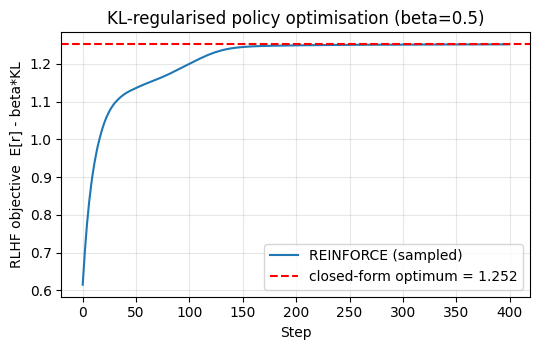

pi_ref : [0.202 0.166 0.091 0.183 0.123 0.136 0.017 0.082]
pi_rl  : [0.029 0.159 0.301 0.01  0.006 0.112 0.244 0.139]
pi_star: [0.03  0.16  0.302 0.007 0.003 0.113 0.245 0.14 ]
total-variation distance(pi_rl, pi_star) = 0.0055
Task C2 (REINFORCE) checks passed.


In [16]:
beta_train = 0.5
theta = np.log(pi_ref).copy()
rng_rl = np.random.RandomState(0)
objective_history = []

for _ in range(400):
    objective_history.append(rlhf_objective(np.exp(log_softmax(theta)), proxy_reward, pi_ref, beta_train))
    theta = reinforce_step(theta, proxy_reward, logp_ref, beta_train, lr=0.5, n_samples=2000, rng=rng_rl)

pi_rl = np.exp(log_softmax(theta))
pi_star = optimal_policy(proxy_reward, pi_ref, beta_train)

opt_val = rlhf_objective(pi_star, proxy_reward, pi_ref, beta_train)
plt.figure(figsize=(5.5, 3.6))
plt.plot(objective_history, label="REINFORCE (sampled)")
plt.axhline(opt_val, color="r", linestyle="--", label=f"closed-form optimum = {opt_val:.3f}")
plt.xlabel("Step"); plt.ylabel("RLHF objective  E[r] - beta*KL")
plt.title(f"KL-regularised policy optimisation (beta={beta_train})")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

tv = 0.5 * np.abs(pi_rl - pi_star).sum()
print("pi_ref :", np.round(pi_ref, 3))
print("pi_rl  :", np.round(pi_rl, 3))
print("pi_star:", np.round(pi_star, 3))
print(f"total-variation distance(pi_rl, pi_star) = {tv:.4f}")

# --- test cases: do not modify ---
assert len(objective_history) == 400
assert objective_history[-1] > objective_history[0] + 0.1
assert tv < 0.05
print("Task C2 (REINFORCE) checks passed.")

### Task C3: Reward hacking and the role of $\beta$

Look at the supplied table above: the candidate `RAMBLER` is extremely long. The reward model has never seen
such lengths, and extrapolates its small positive length weight to give it a **high proxy reward**, while real
humans would find it awful (very negative true reward).

Using the closed-form optimal policy, sweep
`betas = [0.03, 0.1, 0.3, 1, 3, 10]`. For each $\beta$ record

- the expected **proxy** reward $\mathbb{E}_{\pi^*}[r_{proxy}]$,
- the expected **true** reward $\mathbb{E}_{\pi^*}[r_{true}]$,
- the $\mathrm{KL}(\pi^*\Vert\pi_{ref})$,

then plot proxy and true reward against $\beta$ (log x-axis) and describe what you see in Analysis Question Q4.

  beta | KL(pi*||pi_ref) | proxy reward | true reward | P(RAMBLER)
  0.03 |          4.0970 |       2.5976 |    -17.2000 | 1.000
   0.1 |          4.0689 |       2.5951 |    -17.1378 | 0.997
   0.3 |          2.1268 |       2.1780 |     -9.0264 | 0.565
     1 |          0.3196 |       1.2931 |     -0.4234 | 0.084
     3 |          0.0414 |       0.8655 |      0.2163 | 0.031
    10 |          0.0038 |       0.6914 |      0.2582 | 0.020
reference policy: proxy = 0.6153, true = 0.2549


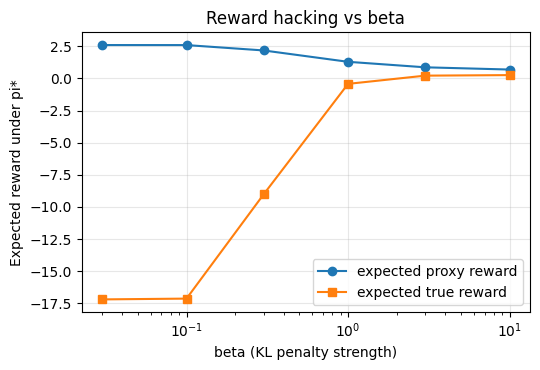

Task C3 checks passed.


In [17]:
betas = [0.03, 0.1, 0.3, 1, 3, 10]
proxy_E, true_E, kl_E = [], [], []

for beta_ in betas:
    pi_b = optimal_policy(proxy_reward, pi_ref, beta_)
    proxy_E.append(pi_b @ proxy_reward)
    true_E.append(pi_b @ true_rew)
    kl_E.append(kl_divergence(pi_b, pi_ref))

print(f"{'beta':>6} | {'KL(pi*||pi_ref)':>15} | {'proxy reward':>12} | {'true reward':>11} | P(RAMBLER)")
for b_, k_, p_, t_ in zip(betas, kl_E, proxy_E, true_E):
    pr = optimal_policy(proxy_reward, pi_ref, b_)[cand_names.index("RAMBLER")]
    print(f"{b_:>6} | {k_:>15.4f} | {p_:>12.4f} | {t_:>11.4f} | {pr:.3f}")
print(f"reference policy: proxy = {pi_ref @ proxy_reward:.4f}, true = {pi_ref @ true_rew:.4f}")

plt.figure(figsize=(5.5, 3.8))
plt.semilogx(betas, proxy_E, "o-", label="expected proxy reward")
plt.semilogx(betas, true_E, "s-", label="expected true reward")
plt.xlabel("beta (KL penalty strength)"); plt.ylabel("Expected reward under pi*")
plt.title("Reward hacking vs beta"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# --- test cases: do not modify ---
assert len(proxy_E) == len(true_E) == len(kl_E) == len(betas)
assert proxy_E[0] > proxy_E[-1], "weaker KL penalty must give a higher proxy reward"
assert true_E[0] < true_E[-1], "...but here that is reward hacking: the TRUE reward gets worse"
assert kl_E[0] > kl_E[-1]
print("Task C3 checks passed.")

### Task C4 (Bonus): Direct Preference Optimisation (DPO)

RLHF needs a separate reward model *and* an RL loop. **DPO** skips both: it optimises the policy **directly on the
preference pairs**. For a chosen response $w$ and rejected response $l$:
$$
L_{DPO}(\theta) = -\frac{1}{M}\sum_m \log\sigma\!\Big(\beta\big[(\log\pi_\theta(w_m)-\log\pi_{ref}(w_m)) - (\log\pi_\theta(l_m)-\log\pi_{ref}(l_m))\big]\Big).
$$

For our softmax policy, with $z_m$ the argument of the sigmoid, the gradient simplifies to
$$\nabla_\theta L = -\frac{\beta}{M}\sum_m \sigma(-z_m)\,(\mathbf{e}_{w_m}-\mathbf{e}_{l_m}),$$
(the $\pi_\theta$ terms cancel!). Implement `dpo_loss_and_grad(theta, logp_ref, idx_w, idx_l, beta)` returning
`(loss, grad)`, verify the gradient numerically, train for 500 steps with `lr = 2.0`, `beta = 0.5`, and compare
the resulting policy's **true** expected reward with the reference policy and with the RLHF policy `pi_rl`.
Here the preference pairs are labelled by the real human-like reward (`true_rew`), *including* comparisons that
involve `RAMBLER`.

In [18]:
ATTEMPT_BONUS = True
rng_dpo = np.random.RandomState(0)
pa = rng_dpo.randint(0, K, 3000); pb = rng_dpo.randint(0, K, 3000)
keep = pa != pb
pa, pb = pa[keep], pb[keep]
a_pref = rng_dpo.rand(len(pa)) < 1 / (1 + np.exp(-(true_rew[pa] - true_rew[pb])))
idx_w = np.where(a_pref, pa, pb); idx_l = np.where(a_pref, pb, pa)


def dpo_loss_and_grad(theta, logp_ref, idx_w, idx_l, beta):
    lp = log_softmax(theta)
    z = beta * ((lp[idx_w] - logp_ref[idx_w]) - (lp[idx_l] - logp_ref[idx_l]))
    loss = np.mean(np.logaddexp(0, -z))
    coef = -beta * sigmoid(-z) / len(z)
    grad = np.zeros(len(theta))
    np.add.at(grad, idx_w, coef)
    np.add.at(grad, idx_l, -coef)
    return loss, grad


# gradient check
th_chk = np.random.RandomState(1).randn(K)
_, g_an = dpo_loss_and_grad(th_chk, logp_ref, idx_w, idx_l, 0.5)
g_nu = numeric_grad(lambda t: dpo_loss_and_grad(t, logp_ref, idx_w, idx_l, 0.5)[0], th_chk)
print("DPO gradient check, max abs diff:", np.max(np.abs(g_an - g_nu)))
assert np.allclose(g_an, g_nu, atol=1e-6)

# training
theta_dpo = np.log(pi_ref).copy()
dpo_losses = []
for _ in range(500):
    loss_, grad_ = dpo_loss_and_grad(theta_dpo, logp_ref, idx_w, idx_l, 0.5)
    dpo_losses.append(loss_)
    theta_dpo = theta_dpo - 2.0 * grad_

pi_dpo_ = np.exp(log_softmax(theta_dpo))
ri = cand_names.index("RAMBLER")
print(f"{'policy':>8} | {'true expected reward':>20} | P(RAMBLER)")
for nm, p_ in [("pi_ref", pi_ref), ("pi_rl", pi_rl), ("pi_dpo", pi_dpo_)]:
    print(f"{nm:>8} | {p_ @ true_rew:>20.4f} | {p_[ri]:.4f}")
print("DPO loss: ", dpo_losses[0], "->", dpo_losses[-1])
if ATTEMPT_BONUS:
    pi_dpo = np.exp(log_softmax(theta_dpo))
    assert pi_dpo @ true_rew > pi_ref @ true_rew
    assert pi_dpo[cand_names.index("RAMBLER")] < pi_ref[cand_names.index("RAMBLER")]
    print("Bonus Task C4 checks passed.")

DPO gradient check, max abs diff: 9.706943582266092e-11
  policy | true expected reward | P(RAMBLER)
  pi_ref |               0.2549 | 0.0166
   pi_rl |              -3.1502 | 0.2443
  pi_dpo |               1.4749 | 0.0000
DPO loss:  0.6931471805599454 -> 0.39490509423889275
Bonus Task C4 checks passed.


# Part D: The Real Thing — `peft` and `bitsandbytes`

Everything you built in Parts A and B exists in the Hugging Face ecosystem:
[`peft`](https://huggingface.co/docs/peft) implements LoRA (and many other adapters) and
[`bitsandbytes`](https://github.com/bitsandbytes-foundation/bitsandbytes) implements 4-bit NF4 quantisation with
double quantisation. **Run this part on Google Colab** (Runtime > Change runtime type > T4 GPU). It downloads small
models (GPT-2 about 0.5 GB, OPT-125M about 0.25 GB).

> **No GPU?** `bitsandbytes` 4-bit loading needs one. In that case do Task D1 (it runs on CPU) and, instead of
> running D2, write 5-6 sentences in the markdown cell under D2 describing what each argument of
> `BitsAndBytesConfig` does and what you would expect `get_memory_footprint()` to show. That written
> answer replaces the D2 code.

### Task D1: LoRA on GPT-2 with `peft`

1. Create a `LoraConfig` with `r=8`, `lora_alpha=16`, `lora_dropout=0.05`, `target_modules=["c_attn"]` (GPT-2's
   fused query/key/value projection), `fan_in_fan_out=True` (GPT-2 stores weights transposed) and
   `task_type="CAUSAL_LM"`, then wrap the model with `get_peft_model`.
2. Call `print_trainable_parameters()`.
3. **Check it against your own formula from Task A1.** GPT-2 small has 12 transformer blocks, and each `c_attn` is
   a $768 \to 2304$ layer. Compute the expected number of trainable parameters with `count_params`-style
   arithmetic and assert that it equals what `peft` reports.

In [23]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "transformers", "peft", "accelerate", "bitsandbytes"])

import torch
from transformers import AutoModelForCausalLM
from peft import LoraConfig, get_peft_model

base_model = AutoModelForCausalLM.from_pretrained("gpt2")
n_total = sum(p.numel() for p in base_model.parameters())

lora_cfg = LoraConfig(r=8, lora_alpha=16, lora_dropout=0.05, target_modules=["c_attn"],
                      fan_in_fan_out=True, task_type="CAUSAL_LM")
peft_model = get_peft_model(base_model, lora_cfg)
peft_model.print_trainable_parameters()

n_trainable = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)

r_d1, d_in_d1, d_out_d1, n_blocks = 8, 768, 2304, 12
expected = n_blocks * r_d1 * (d_in_d1 + d_out_d1)
print("expected from our formula:", f"{expected:,}")
assert n_trainable == expected
print(f"trainable: {n_trainable:,} of {n_total:,} ({100 * n_trainable / n_total:.3f}%)")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

trainable params: 294,912 || all params: 124,734,720 || trainable%: 0.2364
expected from our formula: 294,912
trainable: 294,912 of 124,439,808 (0.237%)


### Task D2: QLoRA with `bitsandbytes`

1. Build a `BitsAndBytesConfig` with `load_in_4bit=True`, `bnb_4bit_quant_type="nf4"`,
   `bnb_4bit_use_double_quant=True` and `bnb_4bit_compute_dtype=torch.float16`.
2. Load `facebook/opt-125m` twice: once in fp16 and once with the 4-bit config
   (`quantization_config=..., device_map="auto"`). Print `get_memory_footprint()` of both in MB and the ratio.
3. Prepare the 4-bit model with `prepare_model_for_kbit_training`, attach LoRA
   (`r=8`, `lora_alpha=16`, `target_modules=["q_proj", "v_proj"]`) and print the trainable parameters.
4. In the markdown cell below the code, answer: **why is the memory ratio smaller than 4x?** (Hint: which
   modules of the model are *not* quantised?)

In [24]:
from transformers import BitsAndBytesConfig
from peft import prepare_model_for_kbit_training

bnb_cfg = BitsAndBytesConfig(
    load_in_4bit=True,                       # store Linear weights in 4 bits
    bnb_4bit_quant_type="nf4",               # NormalFloat-4 code book (instead of uniform fp4)
    bnb_4bit_use_double_quant=True,          # also quantise the per-block absmax constants
    bnb_4bit_compute_dtype=torch.float16,    # de-quantise to fp16 for the matmuls
)

model_fp16 = AutoModelForCausalLM.from_pretrained("facebook/opt-125m", torch_dtype=torch.float16)
model_4bit = AutoModelForCausalLM.from_pretrained("facebook/opt-125m", quantization_config=bnb_cfg, device_map="auto")

mem_fp16 = model_fp16.get_memory_footprint() / 1e6
mem_4bit = model_4bit.get_memory_footprint() / 1e6
print(f"fp16 footprint : {mem_fp16:8.1f} MB")
print(f"4-bit footprint: {mem_4bit:8.1f} MB")
print(f"ratio fp16 / 4-bit = {mem_fp16 / mem_4bit:.2f}x   (ideal for the quantised layers alone would be ~4x)")


emb = model_4bit.get_input_embeddings().weight
print("embedding matrix dtype:", emb.dtype, "| size:", emb.numel() * emb.element_size() / 1e6, "MB")

model_4bit = prepare_model_for_kbit_training(model_4bit)
qlora_model = get_peft_model(
    model_4bit,
    LoraConfig(r=8, lora_alpha=16, lora_dropout=0.05,
               target_modules=["q_proj", "v_proj"], task_type="CAUSAL_LM"),
)
qlora_model.print_trainable_parameters()

config.json:   0%|          | 0.00/651 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  251MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  251MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/137 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

fp16 footprint :    250.5 MB
4-bit footprint:    123.1 MB
ratio fp16 / 4-bit = 2.04x   (ideal for the quantised layers alone would be ~4x)
embedding matrix dtype: torch.float16 | size: 77.217792 MB
trainable params: 294,912 || all params: 125,534,208 || trainable%: 0.2349


**Your answer to D2 step 4 (fill in):**

The memory ratio is well below 4x (it is roughly 2x for OPT-125M) because **only the `nn.Linear` weight matrices inside the transformer blocks are quantised** (q/k/v/out projections and the two feed-forward layers). Several things stay in 16-bit (or higher):

- the **token-embedding matrix** (50,272 x 768 ≈ 38.6M parameters) and the positional embeddings. For a model as small as OPT-125M this single matrix is about a third of all parameters, and the `lm_head` is tied to it and is also kept unquantised;
- all **LayerNorm** weights/biases and the **bias vectors** of the linear layers (tiny, but not quantised);
- the **quantisation constants** themselves: each block of 64 weights has an `absmax` scale (double quantisation compresses these to 8-bit, but they still cost about 0.127 bits/param on top of the 4 bits, i.e. ~0.4–0.5 bytes/param, not exactly 0.5).

So the footprint is `(unquantised part at 2 bytes/param) + (quantised part at ~0.5 bytes/param)`. The quantised part shrinks by ~4x, the rest does not shrink at all, so the overall ratio is a blend. For large models (7B+) the Linear layers dominate and the ratio approaches 3.5–4x; for tiny models the embedding matrix dominates and the ratio is much smaller. (Note also that `prepare_model_for_kbit_training` casts the non-quantised parameters to fp32, which would make the footprint even larger, so we measured the memory *before* calling it.)


# Answers

**Answer Q1. (Rank and scale).**

*Why r = 1 failed and r = 2 succeeded.* The true update `Delta` has rank exactly 2. A LoRA update `(alpha/r) A B` has rank at most `r`, so with `r = 1` the model can only represent the best rank-1 approximation of `Delta` and can never match the second singular direction. In the run, the validation loss was about **2.427** for `r = 1` (versus **5.145** for the un-adapted base, meaning it only removed about half the error), while for `r = 2` it dropped to **0.003215**, a drop of roughly 750x. At `r = 2` the update is expressive enough to represent `Delta` exactly, and what is left is only the label noise.

*Why r = 16 did not help.* Once `r >= rank(Delta)` there is nothing left to capture. The loss for `r = 2, 4, 8, 16` is essentially identical (**0.003215** to **0.003249**) and equals the **noise floor** of the data: with noise std 0.01 on 64 outputs the irreducible loss is `0.5 * 64 * 0.01^2 = 0.0032`. Extra rank only adds parameters (256 -> 2,048) and a tiny bit of overfitting, which is why the validation loss even creeps up very slightly with `r`. Notice that LoRA at `r = 2` (256 trainable parameters) was even slightly better on validation (**0.003215**) than full fine-tuning with all 4,096 parameters (**0.003430**), because the low-rank constraint acts as a regulariser.

*Choosing r in a real model.* The right `r` is the "intrinsic rank" of the task-specific update, which is unknown, so in practice one treats it as a hyper-parameter: start small (typically 8 or 16), evaluate on a validation set, and increase (32, 64, ...) only if validation loss/accuracy is still improving. Use small ranks for simple adaptations (style, format, classification) and larger ranks for tasks that are far from the pre-training distribution (new domain/language, hard reasoning, code); also consider the memory budget (parameters grow linearly in `r`) and which modules you adapt (adapting more modules with small `r` is often better than one module with large `r`). The same sweep as in Task A3 (plot validation loss vs `r`, pick the knee) is the practical recipe.

*What `alpha / r` does.* It is a fixed scaling factor `s` on the low-rank update: `y = xW0 + s * xAB`. Dividing by `r` makes the magnitude of the update roughly independent of the rank, so when you change `r` you do not have to re-tune the learning rate (this is why `alpha = 2r` gave a constant `s = 2` in the sweep). `alpha` therefore controls how strongly the adapter can influence the output.

*Doubling alpha with everything else fixed.* The scale `s` doubles. The adapter's contribution to the output is twice as large for the same `A, B`; moreover the gradients `dA` and `dB` are both multiplied by `s` and the effect of a parameter change on the output is multiplied by `s` again, so for plain gradient descent the effective learning rate of the function-space update grows by about `s^2`, i.e. **roughly 4x faster** early in training. This can speed up learning, but can also make training unstable or overshoot (with Adam the effect is ~2x on the output scale since the optimizer normalises gradient magnitudes). Doubling `alpha` is therefore similar to raising the learning rate, and the two are normally tuned together. It does not change the inference cost: after merging it is just a different `W`.

---

**Answer Q2. (Zero initialisation).**

At the very first step, with `B = 0`:
`dA = s * X^T (dY B^T) = 0` (because `B = 0`), while `dB = s * (XA)^T dY` is **non-zero** as long as `A` is non-zero. So `B` receives gradient immediately and becomes non-zero, after which `A` starts to receive gradient too.

- **Why `B = 0`:** this makes `AB = 0`, so the adapted model is *exactly* the pretrained model at step 0 (we verified in Task A1 that `lora_forward(...) == x @ W0`). Fine-tuning starts from a good point and the first updates are not corrupted by a random perturbation of the pretrained weights.
- **Why `A` is not zero:** `A` has to be non-zero so that `dB = s (XA)^T dY` is non-zero; random `A` also breaks the symmetry between the `r` rank components so that they learn different directions (if all columns of `A` were identical, all rank components would receive identical gradients and the effective rank would stay 1).
- **If both were zero:** `dA = s X^T (dY B^T) = 0` because `B = 0`, and `dB = s (XA)^T dY = 0` because `A = 0`. Both gradients are exactly zero at every step, so the parameters never move, and the model is stuck at the pretrained weights forever (a saddle point at the origin of the product `AB`). Training would silently do nothing.

(Initialising `A = 0` and `B` random would not be stuck in the same way, since then `dA != 0`, but it breaks the symmetry less well; the standard choice, random `A` and zero `B`, is the one that is exactly the base model and trains right from step 1.)

---

**Answer Q3. (What QLoRA saves).**

*Which tensors are where.* In QLoRA the **frozen pretrained weights `W0`** (the Linear layers) are stored in **4-bit NF4** (plus one `absmax` scale per block of 64 values, which with double quantisation is itself stored in 8-bit). The **LoRA matrices `A` and `B`** stay in **higher precision** (16-bit or 32-bit), and so do their gradients and the optimizer state (Adam `m`, `v`); other non-quantised parts (embeddings, LayerNorms, biases) and the activations also stay in 16/32-bit. In the forward pass `W0` is **de-quantised on the fly** to the compute dtype (fp16/bf16) just for the matmul and then discarded.

*Where gradients flow.* Backprop goes *through* the de-quantised `W0` (the gradient with respect to the layer input needs `W0^T`, so the signal can pass to earlier layers), but **no gradient is computed or stored for `W0`**: it is frozen and quantised (4-bit integers are not differentiable parameters anyway). The only tensors that receive a gradient and are updated are **`A` and `B`** (in higher precision).

*How much quantisation error did the adapter recover?* Numbers from Task B3 (validation loss; the full-precision base after LoRA reaches **0.0032**):

| base | before training | after LoRA (r=2) |
|---|---|---|
| fp | 5.1448 | 0.0032 |
| int4 | 5.5220 | 0.3480 |
| nf4 | 5.4513 | 0.2611 |

Quantisation made the *un-adapted* model worse by **0.3772** (int4) and **0.3065** (NF4) over the fp base (**5.1448**). After training, the loss is still **0.3448** (int4) and **0.2579** (NF4) above the fp-LoRA result of **0.0032**, so the adapters recovered only about **9% (int4)** and **16% (NF4)** of the quantisation damage. This is expected: the quantisation error `W_quant - W_base` is an essentially random, **full-rank** matrix, while the rank-2 adapter has to spend its capacity on the (rank-2) task update `Delta` and can only cancel at most a couple of directions of the error. A larger `r` would repair more of it. The conclusion is that LoRA on top of a 4-bit base still fits the new task very well (loss reduced by more than 15x, more than 94%), but it does not make the base perfect again, and a better quantiser (NF4) leaves less damage to repair.

*Why NF4 beat int4.* Trained weights are roughly bell-shaped (Gaussian): most values are near 0 and only a few are large. Uniform int4 spaces its levels evenly over `[-absmax, absmax]`, so many of its levels are spent in the sparsely populated tails, and the dense central region (where most weights are) gets a coarse resolution. NF4 places its 16 levels at **quantiles of the normal distribution**, so there are more levels near 0 where the data is dense and fewer in the tails; each level is used about equally often, which minimises the expected rounding error for bell-shaped data. In my runs on 32,000 Gaussian weights the reconstruction MSE was **0.00840 for NF4 versus 0.01167 for int4** (about 28% lower), and on `W_base` it was **0.000135** versus **0.000180**, which carried through to the lower final loss (**0.2611** vs **0.3480**).

---

**Answer Q4. (Reward hacking).**

*What the plot shows* (closed-form optimal policy for `beta` from 0.03 to 10):

| beta | KL(pi* \|\| pi_ref) | E[proxy] | E[true] | P(RAMBLER) |
|---|---|---|---|---|
| 0.03 | 4.0970 | 2.5976 | -17.2000 | 1.000 |
| 0.1 | 4.0689 | 2.5951 | -17.1378 | 0.997 |
| 0.3 | 2.1268 | 2.1780 | -9.0264 | 0.565 |
| 1 | 0.3196 | 1.2931 | -0.4234 | 0.084 |
| 3 | 0.0414 | 0.8655 | 0.2163 | 0.031 |
| 10 | 0.0038 | 0.6914 | 0.2582 | 0.020 |

The **proxy reward falls monotonically as `beta` grows** (**2.5976** -> **0.6914**), because a stronger KL penalty holds the policy close to the reference and gives it less freedom to chase the reward model. The **true reward goes the opposite way**: it is hugely negative for small `beta` (**-17.2000**), crosses zero around `beta` ≈ 1–3, and ends up at about **+0.2582** (the reference policy itself scores **0.2549**). The KL to the reference falls from **4.0970** to nearly **0.0038**. So the gap between "what the reward model believes" and "what humans want" is largest exactly where the optimiser is least constrained.

*Why small beta is a disaster.* With `beta -> 0` the optimum is `argmax` of the proxy reward. The reward model is linear with a small positive length weight (about 0.2) and was only ever trained on lengths clipped to `[-1.5, 1.5]`; for the `RAMBLER` (length 6) it **extrapolates** that weight far outside the data it has seen and gives it the highest proxy reward of all candidates (**2.60**, higher than the really great answer at **1.85**). Real humans, however, hate extreme rambling (`-(6-1.5)^2 = -20.25`), so its true reward is **-17.20**. The policy optimiser finds this weak spot of the reward model and puts all of its probability on `RAMBLER` (P = **1.000** at `beta = 0.03`): this is **reward hacking / Goodhart's law**: when a proxy is optimised hard enough, it stops being a good measure.

*How larger beta protects, and its price.* The KL penalty makes the optimum `pi* ∝ pi_ref exp(r/beta)`, so a candidate's probability can only rise above its reference value in proportion to `exp(r/beta)`. A large `beta` flattens that tilt: `RAMBLER` starts with only **1.7%** probability under `pi_ref`, so it cannot be amplified much (P = **0.084** at `beta = 1`, **0.020** at `beta = 10`). The policy stays in the region where the reward model was trained and is therefore trustworthy. The **price** is that you also give up real improvement: at `beta = 10` the proxy reward is only **0.6914** versus **0.6153** for the reference, so the model has barely moved and we get little of the alignment benefit; it is a trade-off between exploiting the reward model and staying safe. Beta must be tuned (for example by tracking a held-out/true reward or human evaluations).

*Other ways to reduce reward hacking* (any one is enough): train a **reward-model ensemble** and optimise the mean or a pessimistic (e.g. minimum / mean − std) reward; **early stopping** of the RL run based on held-out human evaluation; **iterate**: collect new human comparisons on the *current policy's* outputs (including exploited ones such as long rambles) and retrain the reward model; clip or normalise the reward, add explicit **length penalties**, or use best-of-n with small n instead of full RL.

---

**Answer Q5. (RLHF vs DPO).**

*Two things RLHF needs that DPO does not:*
1. A **separate, explicitly trained reward model** (the Bradley–Terry model of Task C1), which has to be trained, stored and kept in memory during policy training. DPO uses the preference pairs directly through its implicit reward `beta (log pi - log pi_ref)`.
2. An **online reinforcement-learning loop**: sampling responses from the current policy, scoring them with the reward model, and running a policy-gradient algorithm (REINFORCE/PPO with baselines/critic, KL shaping, many hyper-parameters, high variance and instability). DPO is a simple supervised-style loss on a fixed dataset and needs no sampling during training (only log-probabilities of the chosen/rejected responses under the policy and the reference).

*A situation where RLHF is still preferable:* when you need to **go beyond the fixed preference dataset**. DPO is offline: it can only learn from the pairs it is given, whereas RLHF samples *new* responses from the evolving policy and can score them with the reward model, so it can explore and keeps improving on-policy; and the reward model can also be **reused** (best-of-n sampling, filtering/ranking data, monitoring, evaluation). It is also the natural choice when the reward comes from an automatic or verifiable signal (unit tests, a maths checker, a safety classifier) or when you have a lot of unlabelled prompts but little preference data, since a reward model can be applied to unlimited new prompts. (In contrast DPO is preferable when you have a good static preference dataset and want a simpler, cheaper and more stable pipeline.)